In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sb

In [6]:
data=pd.read_excel("/content/drive/MyDrive/content/machine learning/student_dataset.xlsx")
data.head()

,student_id,age,enroll_date,exam_season,courses_enrolled,completed_assignments,completion_rate,login_frequency,last_activity_days_ago,forum_posts_count,label
0,STU00001,26,2024-01-13,0,3,5,0.3571,5.29,10,5,0
1,STU00002,23,2024-05-05,0,6,0,0.0000,0.84,7,0,1
2,STU00003,17,2024-03-12,0,3,1,0.0435,1.79,36,0,1
3,STU00004,23,2024-12-12,0,6,13,0.4396,0.78,9,0,1
4,STU00005,20,2024-02-14,0,5,5,0.2078,0.92,11,0,1


In [7]:
data.columns

Index(['student_id', 'age', 'enroll_date', 'exam_season', 'courses_enrolled',
       'completed_assignments', 'completion_rate', 'login_frequency',
       'last_activity_days_ago', 'forum_posts_count', 'label'],
      dtype='object')

In [8]:
data.describe()

,age,exam_season,courses_enrolled,completed_assignments,completion_rate,login_frequency,last_activity_days_ago,forum_posts_count,label
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000
mean,23.736600,0.094000,3.999400,5.188400,0.260985,3.453820,9.3564,4.212200,0.659200
std,4.583211,0.291858,1.997348,6.109466,0.249010,3.248316,9.4361,4.270131,0.474026
min,17.000000,0.000000,1.000000,0.000000,0.000000,0.100000,1.0000,0.000000,0.000000
25%,20.000000,0.000000,2.000000,1.000000,0.053900,0.980000,2.0000,1.000000,0.000000
50%,24.000000,0.000000,4.000000,3.000000,0.206700,2.440000,6.0000,3.000000,1.000000
75%,27.000000,0.000000,6.000000,7.000000,0.389025,4.942500,13.0000,6.000000,1.000000
max,40.000000,1.000000,7.000000,35.000000,1.000000,14.000000,70.0000,24.000000,1.000000


In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   student_id              5000 non-null   object 
 1   age                     5000 non-null   int64  
 2   enroll_date             5000 non-null   object 
 3   exam_season             5000 non-null   int64  
 4   courses_enrolled        5000 non-null   int64  
 5   completed_assignments   5000 non-null   int64  
 6   completion_rate         5000 non-null   float64
 7   login_frequency         5000 non-null   float64
 8   last_activity_days_ago  5000 non-null   int64  
 9   forum_posts_count       5000 non-null   int64  
 10  label                   5000 non-null   int64  
dtypes: float64(2), int64(7), object(2)
memory usage: 429.8+ KB


In [10]:
data["enroll_date"]=pd.to_datetime(data["enroll_date"])

In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   student_id              5000 non-null   object        
 1   age                     5000 non-null   int64         
 2   enroll_date             5000 non-null   datetime64[ns]
 3   exam_season             5000 non-null   int64         
 4   courses_enrolled        5000 non-null   int64         
 5   completed_assignments   5000 non-null   int64         
 6   completion_rate         5000 non-null   float64       
 7   login_frequency         5000 non-null   float64       
 8   last_activity_days_ago  5000 non-null   int64         
 9   forum_posts_count       5000 non-null   int64         
 10  label                   5000 non-null   int64         
dtypes: datetime64[ns](1), float64(2), int64(7), object(1)
memory usage: 429.8+ KB


In [13]:
data.head(2)

,student_id,age,enroll_date,exam_season,courses_enrolled,completed_assignments,completion_rate,login_frequency,last_activity_days_ago,forum_posts_count,label
0,STU00001,26,2024-01-13,0,3,5,0.3571,5.29,10,5,0
1,STU00002,23,2024-05-05,0,6,0,0.0000,0.84,7,0,1


In [15]:
data["enroll_month"]=pd.to_datetime(data["enroll_date"]).dt.month
data["enroll_dayofweek"]=pd.to_datetime(data["enroll_date"]).dt.dayofweek

In [17]:
data.head(2)

,student_id,age,enroll_date,exam_season,courses_enrolled,completed_assignments,completion_rate,login_frequency,last_activity_days_ago,forum_posts_count,label,enroll_month,enroll_dayofweek
0,STU00001,26,2024-01-13,0,3,5,0.3571,5.29,10,5,0,1,5
1,STU00002,23,2024-05-05,0,6,0,0.0000,0.84,7,0,1,5,6


In [18]:
import seaborn as sns

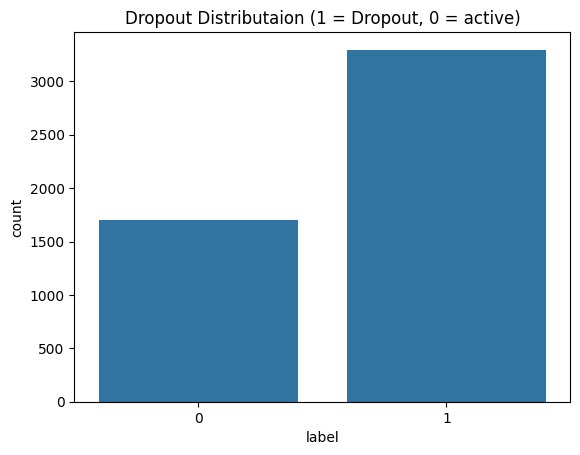

In [19]:
sns.countplot(x="label",data=data)
plt.title("Dropout Distributaion (1 = Dropout, 0 = active)")
plt.show()

In [21]:
data["label"].value_counts()

,count
label,
1,3296
0,1704


In [22]:
data["label"].value_counts(normalize=True)*100

,proportion
label,
1,65.92
0,34.08


In [23]:
data.columns

Index(['student_id', 'age', 'enroll_date', 'exam_season', 'courses_enrolled',
       'completed_assignments', 'completion_rate', 'login_frequency',
       'last_activity_days_ago', 'forum_posts_count', 'label', 'enroll_month',
       'enroll_dayofweek'],
      dtype='object')

In [36]:
num_cols=["age","courses_enrolled","completed_assignments","login_frequency",
          "completion_rate","last_activity_days_ago","forum_posts_count"]

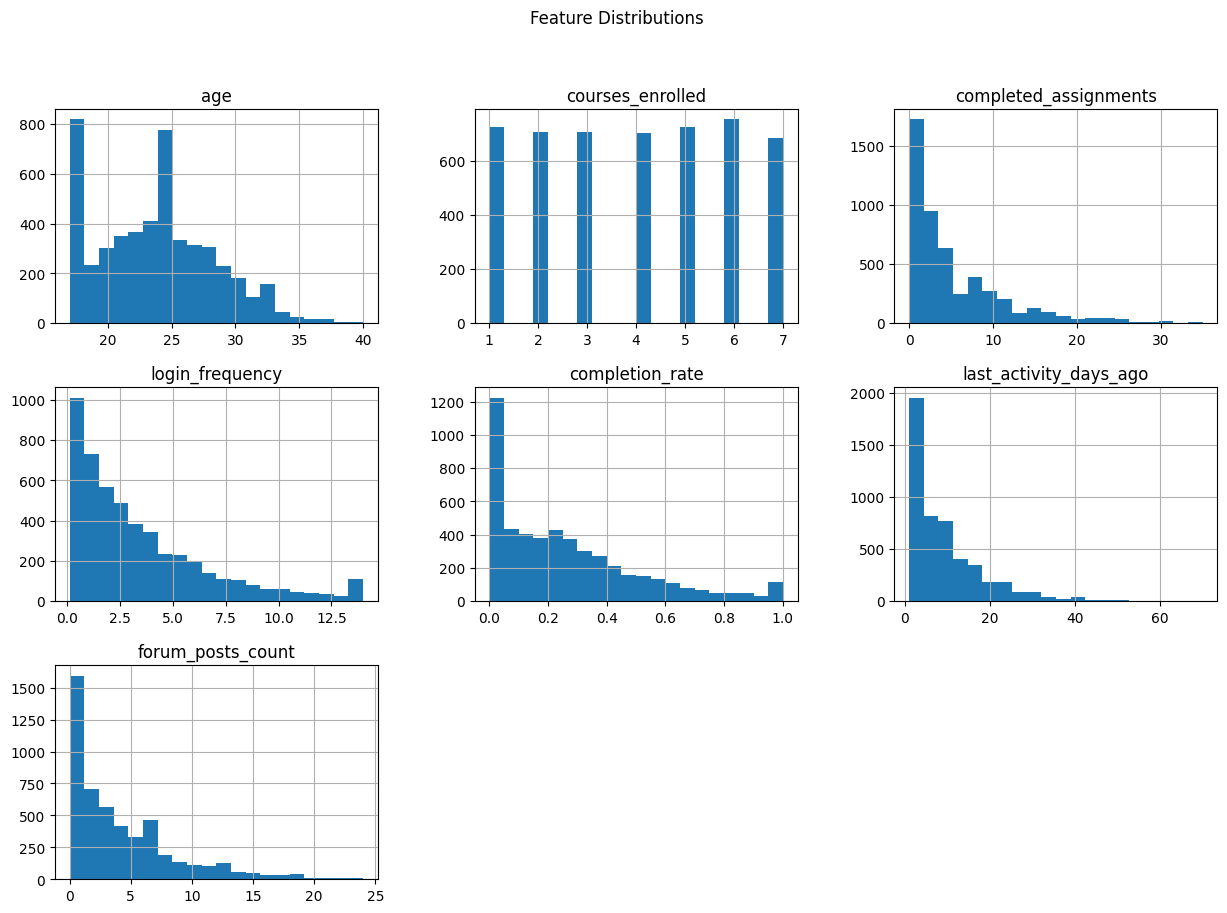

In [37]:
data[num_cols].hist(bins=20, figsize=(15, 10))

plt.suptitle("Feature Distributions")
plt.show()

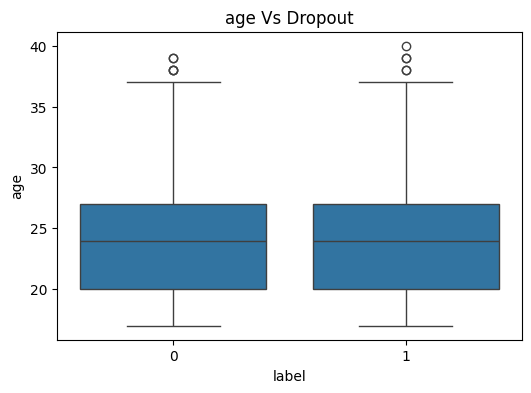

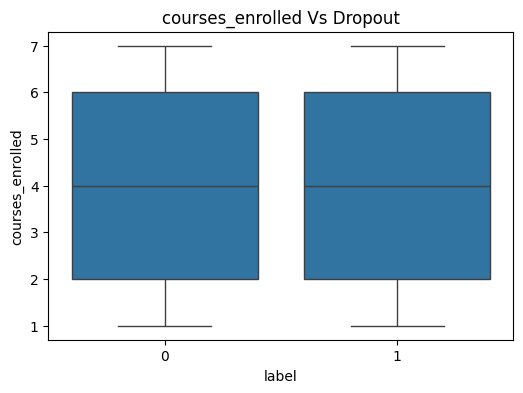

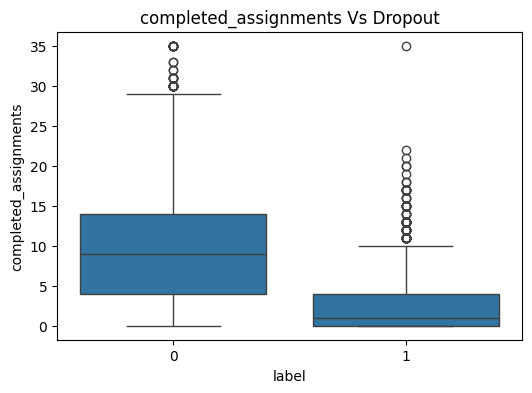

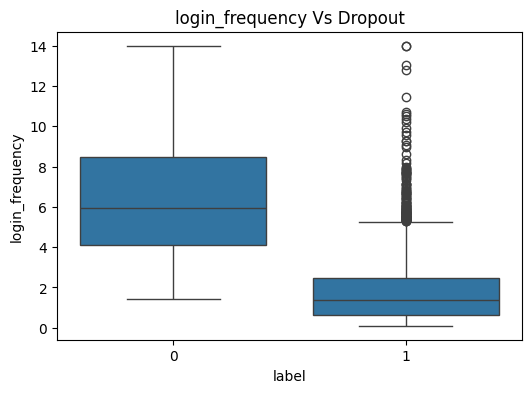

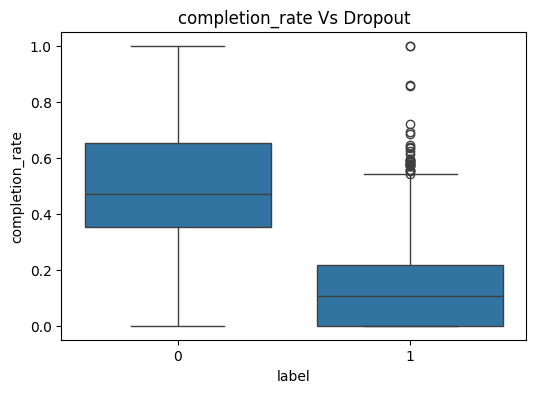

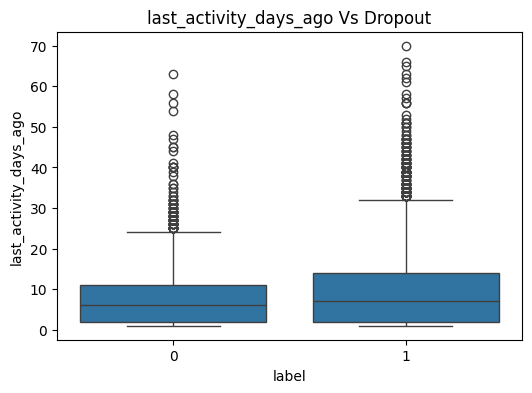

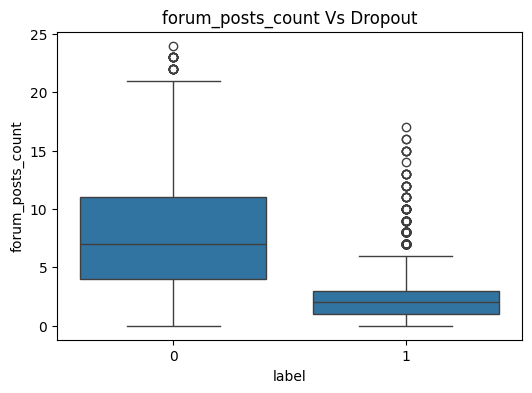

In [38]:
for col in num_cols:
  plt.figure(figsize=(6,4))
  sns.boxplot(x="label",y=col,data=data)
  plt.title(f"{col} Vs Dropout")
  plt.show()

In [42]:
num_cols + ["label"]

['age',
 'courses_enrolled',
 'completed_assignments',
 'login_frequency',
 'completion_rate',
 'last_activity_days_ago',
 'forum_posts_count',
 'label']

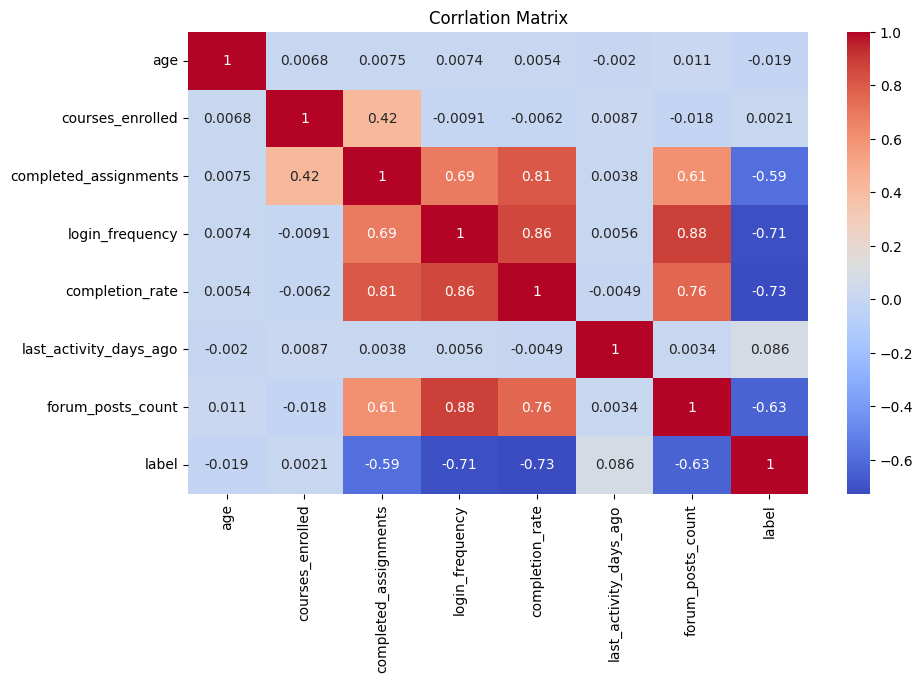

In [43]:
plt.figure(figsize=(10,6))

sns.heatmap(data[num_cols + ["label"]].corr(),annot=True,cmap="coolwarm")
plt.title("Corrlation Matrix")
plt.show()

In [45]:
grouped = data.groupby("label")[num_cols].mean()

grouped

,age,courses_enrolled,completed_assignments,login_frequency,completion_rate,last_activity_days_ago,forum_posts_count
label,,,,,,,
0,23.856808,3.993545,10.214789,6.668122,0.512990,8.231808,7.980634
1,23.674454,4.002427,2.589806,1.792057,0.130701,9.937803,2.263956


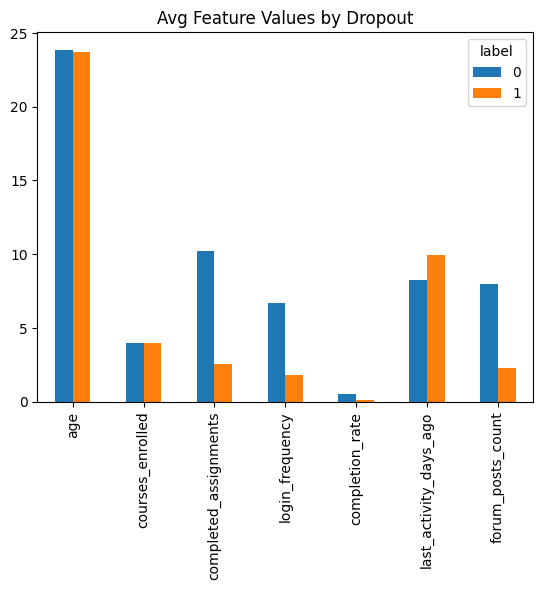

In [46]:
grouped.T.plot(kind="bar")
plt.title("Avg Feature Values by Dropout")
plt.show()

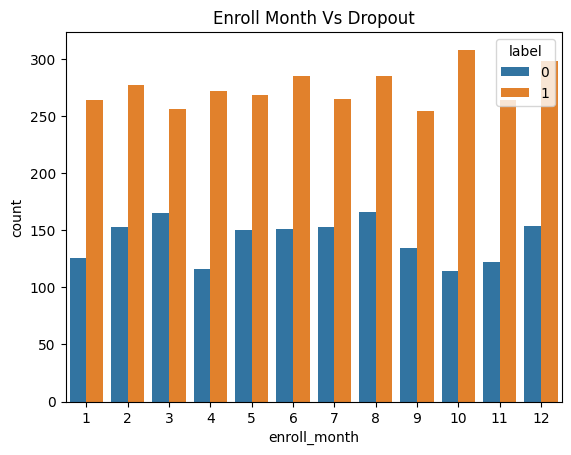

In [47]:
sns.countplot(x="enroll_month",hue="label",data=data)
plt.title("Enroll Month Vs Dropout")
plt.show()

In [50]:
data.head(2)

,student_id,age,enroll_date,exam_season,courses_enrolled,completed_assignments,completion_rate,login_frequency,last_activity_days_ago,forum_posts_count,label,enroll_month,enroll_dayofweek
0,STU00001,26,2024-01-13,0,3,5,0.3571,5.29,10,5,0,1,5
1,STU00002,23,2024-05-05,0,6,0,0.0000,0.84,7,0,1,5,6


In [52]:
data["engagement_score"]=( data["login_frequency"]*0.4 +data["completion_rate"]*0.4+data["forum_posts_count"]*0.2)

In [53]:
data["engagement_score"]

,engagement_score
0,3.25884
1,0.33600
2,0.73340
3,0.48784
4,0.45112
...,...
4995,7.48548
4996,2.76636
4997,3.30968
4998,2.52236


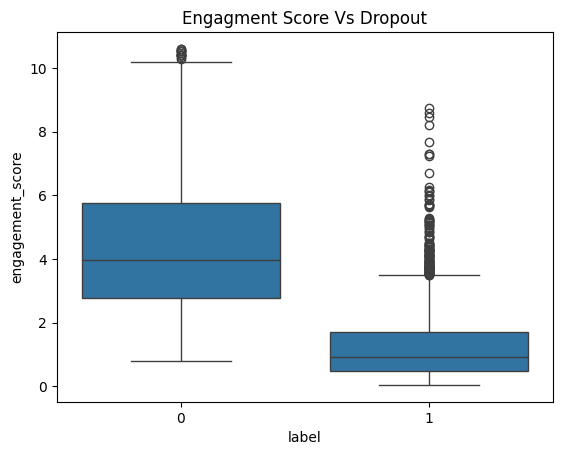

In [55]:
sns.boxplot(x="label",y="engagement_score",data=data)
plt.title("Engagment Score Vs Dropout")
plt.show()

In [56]:
Features = [
    "completion_rate",
    "login_frequency",
    "last_activity_days_ago",
    "courses_enrolled",
    "forum_posts_count",
    "engagement_score"
]

In [57]:
X=data[Features]

In [58]:
X

,completion_rate,login_frequency,last_activity_days_ago,courses_enrolled,forum_posts_count,engagement_score
0,0.3571,5.29,10,3,5,3.25884
1,0.0000,0.84,7,6,0,0.33600
2,0.0435,1.79,36,3,0,0.73340
3,0.4396,0.78,9,6,0,0.48784
4,0.2078,0.92,11,5,0,0.45112
...,...,...,...,...,...,...
4995,0.6537,11.06,1,2,14,7.48548
4996,0.2559,5.16,15,2,3,2.76636
4997,0.2242,5.05,5,3,6,3.30968
4998,0.2659,4.04,1,1,4,2.52236


In [59]:
y=data["label"]

In [60]:
y

,label
0,0
1,1
2,1
3,1
4,1
...,...
4995,0
4996,1
4997,0
4998,0


In [61]:
from sklearn.model_selection import train_test_split

X_train,X_test,Y_train,y_test=train_test_split(X,y,test_size=0.2,stratify=y)

In [62]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [63]:
rf=RandomForestClassifier()

In [71]:
rf_params={
    'n_estimators':[100,200],
    "max_depth":[4,6,8],
    "min_samples_split":[2,5],
    "min_samples_leaf":[1,2]
}

In [72]:
rf_grid=GridSearchCV(
    rf,
    rf_params,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

In [73]:
rf_grid.fit(X_train,Y_train)

GridSearchCV(cv=3, estimator=RandomForestClassifier(), n_jobs=-1,
             param_grid={'max_depth': [4, 6, 8], 'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='accuracy')

In [74]:
best_rf=rf_grid.best_estimator_

In [75]:
print("Best RF params: ",rf_grid.best_params_)

Best RF params:  {'max_depth': 6, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [76]:
from xgboost import XGBRFClassifier

In [77]:
xgb=XGBRFClassifier(
    eval_metric="logloss",
    use_label_encoder=False
)

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: FutureWarning: `XGBRFClassifier` is deprecated and will be removed in a future release. The estimator is a thin wrapper over the boosting interface and does not implement a conventional random forest; features like early stopping are unsupported. Set `num_parallel_tree` along with `n_estimators=1` on the corresponding boosting estimator instead, or use a dedicated random forest implementation like those in `sklearn.ensemble`.
  return func(**kwargs)


In [79]:
xgb_params={
    "n_estimators":[100,200],
    "max_depth":[3,5,7],
    "min_samples_split":[0.05,0.1],
    "min_samples_leaf":[0.8,1]
}

In [81]:
xgb_grid = GridSearchCV(
    estimator=xgb,
    param_grid=xgb_params,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

In [82]:
xgb_grid.fit(X_train,Y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: FutureWarning: `XGBRFClassifier` is deprecated and will be removed in a future release. The estimator is a thin wrapper over the boosting interface and does not implement a conventional random forest; features like early stopping are unsupported. Set `num_parallel_tree` along with `n_estimators=1` on the corresponding boosting estimator instead, or use a dedicated random forest implementation like those in `sklearn.ensemble`.
  return func(**kwargs)
/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: FutureWarning: `XGBRFClassifier` is deprecated and will be removed in a future release. The estimator is a thin wrapper over the boosting interface and does not implement a conventional random forest; features like early stopping are unsupported. Set `num_parallel_tree` along with `n_estimators=1` on the corresponding boosting estimator instead, or use a dedicated random forest implementation like those in `sklearn.ensem

GridSearchCV(cv=3,
             estimator=XGBRFClassifier(base_score=None, booster=None,
                                       callbacks=None, colsample_bylevel=None,
                                       colsample_bytree=None, device=None,
                                       early_stopping_rounds=None,
                                       enable_categorical=True,
                                       eval_metric='logloss',
                                       feature_types=None, feature_weights=None,
                                       gamma=None, grow_policy=None,
                                       importance_type=None,
                                       interaction_constraints=None,
                                       max_bin=None, m...
                                       max_delta_step=None, max_depth=None,
                                       max_leaves=None, min_child_weight=None,
                                       missing=nan, monotone_constraints=None,
                                       multi_strategy=None, n_estimators=None,
                                       n_jobs=None, num_parallel_tree=None,
                                       objective='binary:logistic',
                                       random_state=None, ...),
             n_jobs=-1,
             param_grid={'max_depth': [3, 5, 7], 'min_samples_leaf': [0.8, 1],
                         'min_samples_split': [0.05, 0.1],
                         'n_estimators': [100, 200]},
             scoring='accuracy')

In [83]:
best_xgb=xgb_grid.best_estimator_

In [86]:
print("Best XGB Params : ",xgb_grid.best_params_)

Best XGB Params :  {'max_depth': 5, 'min_samples_leaf': 0.8, 'min_samples_split': 0.05, 'n_estimators': 100}


In [87]:
from sklearn.metrics import accuracy_score

In [88]:
def evaluate_model(model,X_test,y_test,name):
  preds=model.predict(X_test)
  print(f"{name} Results:")
  print("Accuracy:",accuracy_score(y_test,preds))

In [89]:
evaluate_model(best_rf,X_test,y_test,"Random Forest")
evaluate_model(best_xgb,X_test,y_test,"XGBoost")

Random Forest Results:
Accuracy: 0.925
XGBoost Results:
Accuracy: 0.925


In [91]:
best_rf.feature_importances_

array([0.44164924, 0.24182996, 0.03097962, 0.00401641, 0.0872764 ,
       0.19424837])

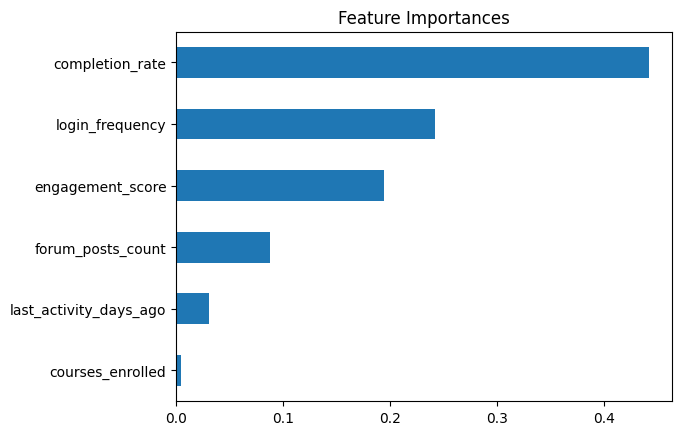

In [95]:
rf_importance = pd.Series(
    best_rf.feature_importances_,
    index=Features
)
rf_importance.sort_values().plot(kind="barh",title="Feature Importances")
plt.show()

In [96]:
import joblib

In [97]:
best_model=best_rf

In [98]:
joblib.dump(best_model,"student_dropout_model.pkl")

['student_dropout_model.pkl']

In [99]:
joblib.dump(Features,"model_features.pkl")

['model_features.pkl']

In [100]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, precision_recall_curve, f1_score)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

RS = 42

In [101]:
df = data.copy()

df["days_since_enroll"] = (df["enroll_date"].max() - df["enroll_date"]).dt.days
df["assignments_per_course"] = df["completed_assignments"] / df["courses_enrolled"]
df["logins_per_course"]      = df["login_frequency"] / df["courses_enrolled"]
df["posts_per_course"]       = df["forum_posts_count"] / df["courses_enrolled"]
df["is_inactive_14d"]        = (df["last_activity_days_ago"] > 14).astype(int)
df["zero_progress"]          = (df["completion_rate"] == 0).astype(int)

FEATURES = [
    "age", "exam_season", "courses_enrolled", "completed_assignments",
    "completion_rate", "login_frequency", "last_activity_days_ago", "forum_posts_count",
    "enroll_month", "enroll_dayofweek", "days_since_enroll",
    "assignments_per_course", "logins_per_course", "posts_per_course",
    "is_inactive_14d", "zero_progress",
]
X = df[FEATURES]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RS)
print(X_train.shape, X_test.shape)

(4000, 16) (1000, 16)


In [102]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

models = {
    "LogReg": Pipeline([("sc", StandardScaler()),
                        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "RandomForest": RandomForestClassifier(n_estimators=300, max_depth=8,
                        class_weight="balanced", random_state=RS, n_jobs=-1),
    "HistGB": HistGradientBoostingClassifier(random_state=RS),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                        subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                        random_state=RS, n_jobs=-1),
}

rows = []
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, n_jobs=-1,
                       scoring=["accuracy", "f1", "recall", "roc_auc"])
    rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in ["accuracy","f1","recall","roc_auc"]}})
results = pd.DataFrame(rows).set_index("model").round(4).sort_values("roc_auc", ascending=False)
results

,accuracy,f1,recall,roc_auc
model,,,,
XGBoost,0.9210,0.9405,0.9469,0.9805
RandomForest,0.9190,0.9382,0.9340,0.9799
HistGB,0.9175,0.9376,0.9401,0.9788
LogReg,0.8968,0.9203,0.9044,0.9662


In [103]:
param_dist = {
    "n_estimators":     [200, 300, 500, 800],
    "max_depth":        [3, 4, 5, 6],
    "learning_rate":    [0.01, 0.03, 0.05, 0.1],
    "subsample":        [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5, 10],
    "gamma":            [0, 0.1, 0.3, 1],
    "reg_lambda":       [1, 3, 5, 10],
}

search = RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss", random_state=RS, n_jobs=-1),
    param_distributions=param_dist, n_iter=40, scoring="roc_auc",
    cv=cv, random_state=RS, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)

best_model = search.best_estimator_
print("Best params:", search.best_params_)
print("CV ROC-AUC :", round(search.best_score_, 4))

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best params: {'subsample': 1.0, 'reg_lambda': 1, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.03, 'gamma': 0.1, 'colsample_bytree': 0.6}
CV ROC-AUC : 0.9821


In [104]:
from sklearn.model_selection import cross_val_predict

oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best_thr = thr[np.argmax(f1s[:-1])]
print("Best threshold (max F1):", round(float(best_thr), 3))

Best threshold (max F1): 0.512


ROC-AUC: 0.9834
F1     : 0.9482
              precision    recall  f1-score   support

      Active       0.92      0.88      0.90       341
     Dropout       0.94      0.96      0.95       659

    accuracy                           0.93      1000
   macro avg       0.93      0.92      0.92      1000
weighted avg       0.93      0.93      0.93      1000



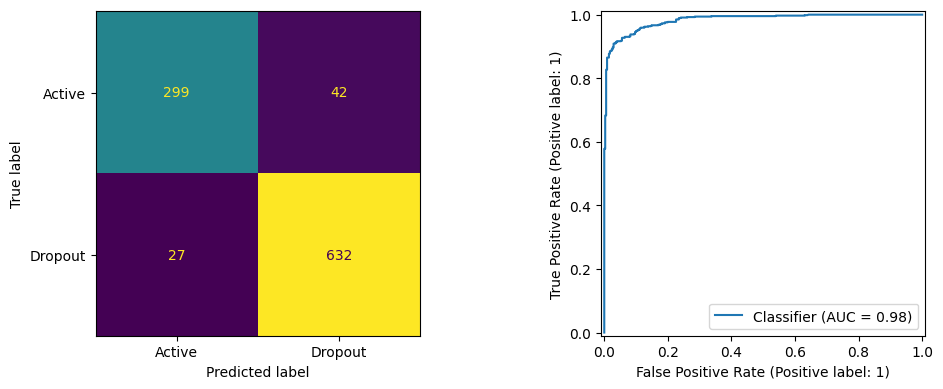

In [105]:
best_model.fit(X_train, y_train)
proba = best_model.predict_proba(X_test)[:, 1]
pred  = (proba >= best_thr).astype(int)

print("ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
print("F1     :", round(f1_score(y_test, pred), 4))
print(classification_report(y_test, pred, target_names=["Active", "Dropout"]))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Active","Dropout"]).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[1])
plt.tight_layout(); plt.show()

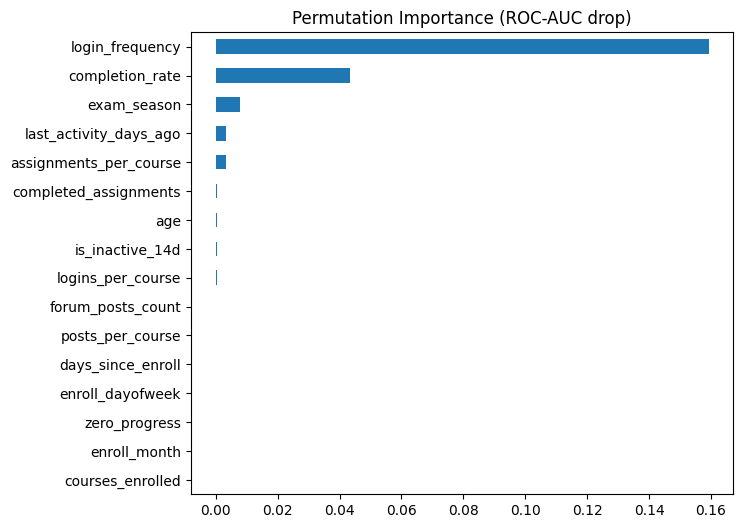

In [106]:
pi = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                            n_repeats=10, random_state=RS, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(7, 6), title="Permutation Importance (ROC-AUC drop)")
plt.show()

In [107]:
import joblib

final_model = XGBClassifier(**search.best_params_, eval_metric="logloss", random_state=RS, n_jobs=-1)
final_model.fit(X, y)

joblib.dump({"model": final_model, "features": FEATURES, "threshold": float(best_thr)},
            "student_dropout_model_v2.pkl")
print("saved")

saved


In [108]:
bundle = joblib.load("student_dropout_model_v2.pkl")

def predict_dropout(row: dict, enroll_ref_date):
    d = pd.DataFrame([row])
    d["enroll_date"] = pd.to_datetime(d["enroll_date"])
    d["enroll_month"] = d["enroll_date"].dt.month
    d["enroll_dayofweek"] = d["enroll_date"].dt.dayofweek
    d["days_since_enroll"] = (pd.to_datetime(enroll_ref_date) - d["enroll_date"]).dt.days
    d["assignments_per_course"] = d["completed_assignments"] / d["courses_enrolled"]
    d["logins_per_course"] = d["login_frequency"] / d["courses_enrolled"]
    d["posts_per_course"] = d["forum_posts_count"] / d["courses_enrolled"]
    d["is_inactive_14d"] = (d["last_activity_days_ago"] > 14).astype(int)
    d["zero_progress"] = (d["completion_rate"] == 0).astype(int)
    p = bundle["model"].predict_proba(d[bundle["features"]])[:, 1][0]
    return {"dropout_probability": round(float(p), 3), "dropout": int(p >= bundle["threshold"])}